
💖 Recorrido iluminado para: 'Ana' (Fuerza: 2, Agilidad: 1, Velocidad: 3)
🛤️ Ruta de nodos: evaluacion_inicial ➔ circuito_fuerza_baja ➔ test_agilidad_baja ➔ test_velocidad_corta ➔ test_resistencia_base ➔ generar_reporte


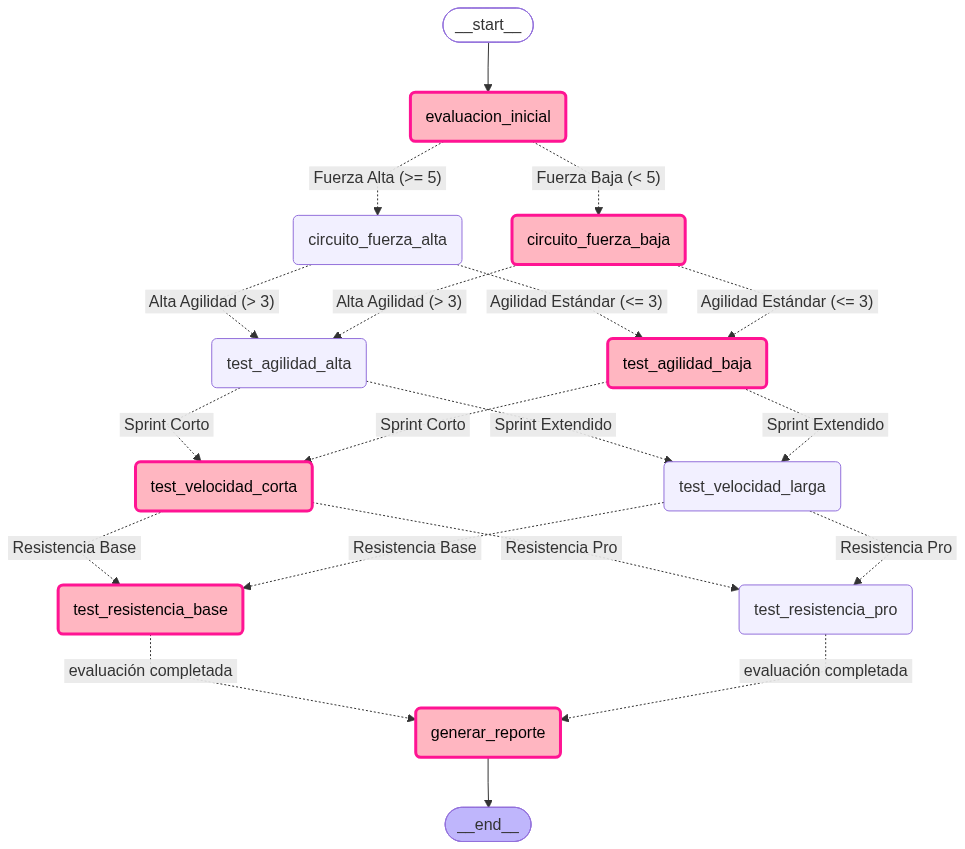


[🏋️ Test de Habilidades] Atleta: 'Ana' | Fuerza: 2 | Agilidad: 1 | Velocidad: 3
  ↳ ⚡ [Fase 1 - Fuerza Baja]: Entrenando potencia básica...
    ↳ 🏃 [Fase 2 - Agilidad Estándar]: Test de reflejos en conos.
      ↳ ⏱️ [Fase 3 - Sprint Corto]: Prueba de 50 metros planos.
        ↳ 🛡️ [Fase 4 - Resistencia Base]: Test aeróbico nivel estándar.
📤 Resultado: {'nombre_atleta': 'Ana', 'categoria': 'Atleta Estándar: ana', 'metricas': {'fuerza': 2, 'agilidad': 1, 'velocidad': 3, 'resistencia': 1}, 'logros': 'Bloque de Fuerza Básica Superado + Agilidad Estándar + Sprint Corto + Resistencia Base'}

💖 Recorrido iluminado para: 'Carlos Ruiz' (Fuerza: 4, Agilidad: 2, Velocidad: 11)
🛤️ Ruta de nodos: evaluacion_inicial ➔ circuito_fuerza_baja ➔ test_agilidad_baja ➔ test_velocidad_larga ➔ test_resistencia_base ➔ generar_reporte


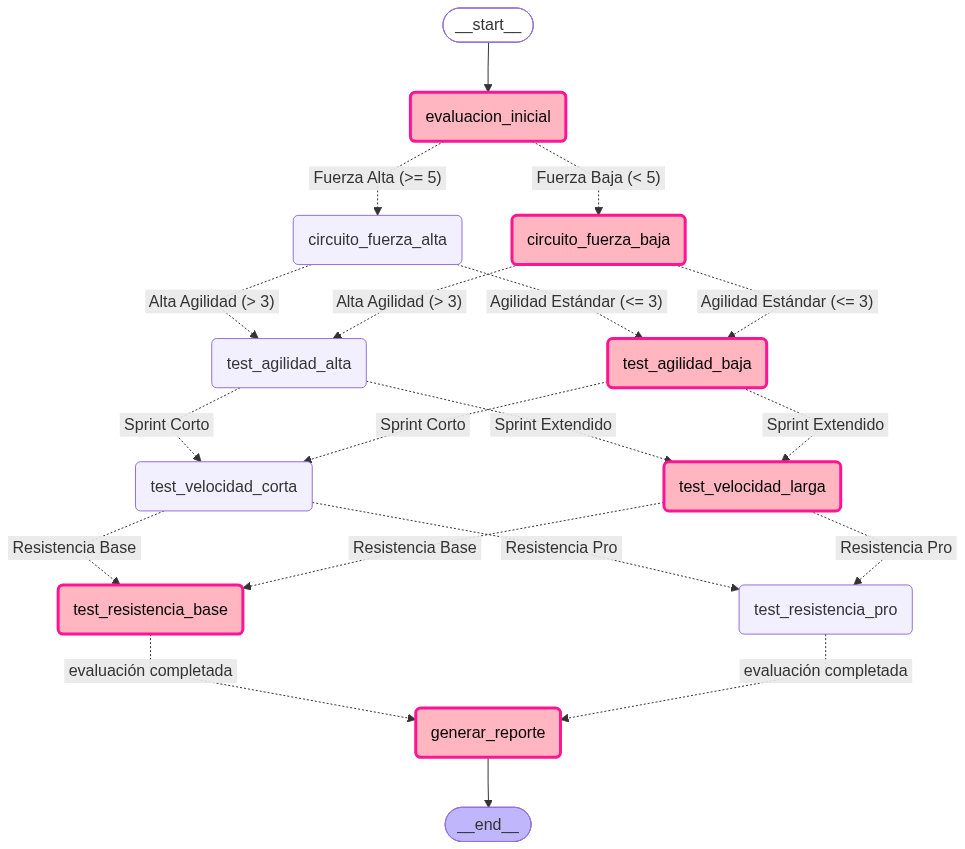


[🏋️ Test de Habilidades] Atleta: 'Carlos Ruiz' | Fuerza: 4 | Agilidad: 2 | Velocidad: 11
  ↳ ⚡ [Fase 1 - Fuerza Baja]: Entrenando potencia básica...
    ↳ 🏃 [Fase 2 - Agilidad Estándar]: Test de reflejos en conos.
      ↳ 🚀 [Fase 3 - Sprint Extendido]: Prueba de 100 metros con vallas.
        ↳ 🛡️ [Fase 4 - Resistencia Base]: Test aeróbico nivel estándar.
📤 Resultado: {'nombre_atleta': 'Carlos Ruiz', 'categoria': 'Atleta Estándar: carlos ruiz', 'metricas': {'fuerza': 4, 'agilidad': 2, 'velocidad': 11, 'resistencia': 2}, 'logros': 'Bloque de Fuerza Básica Superado + Agilidad Estándar + Sprint Extendido + Resistencia Base'}

💖 Recorrido iluminado para: 'Valentina Montenegro de la Santísima Trinidad' (Fuerza: 17, Agilidad: 6, Velocidad: 45)
🛤️ Ruta de nodos: evaluacion_inicial ➔ circuito_fuerza_alta ➔ test_agilidad_alta ➔ test_velocidad_larga ➔ test_resistencia_pro ➔ generar_reporte


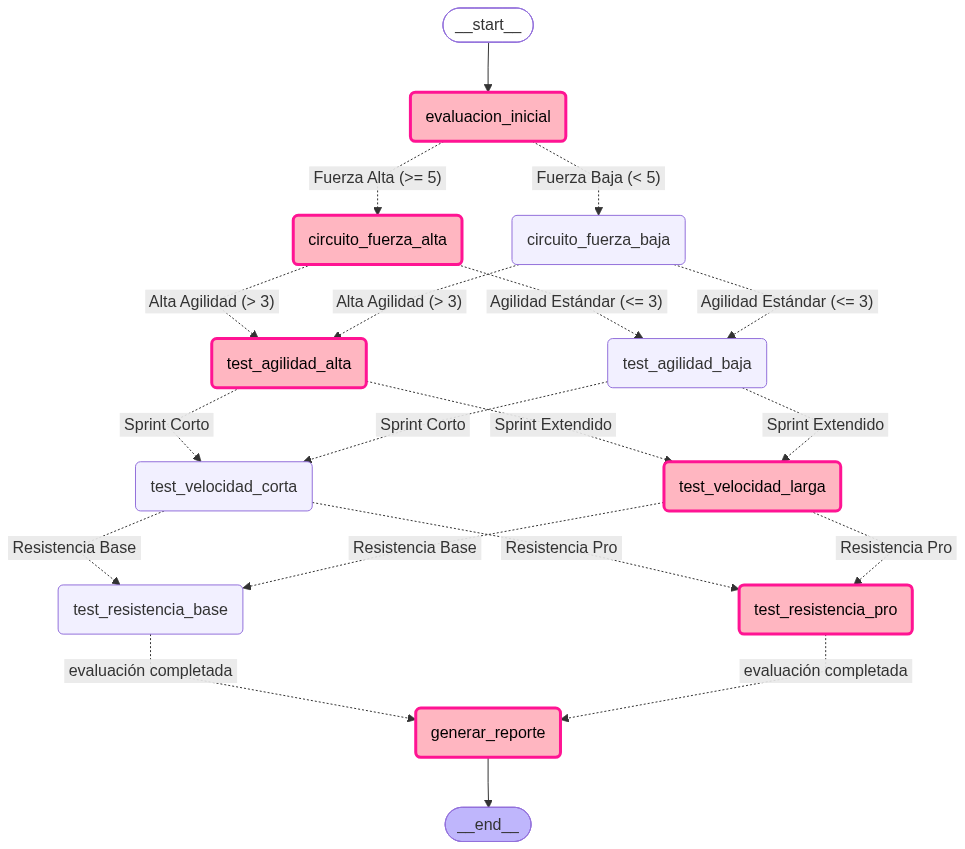


[🏋️ Test de Habilidades] Atleta: 'Valentina Montenegro de la Santísima Trinidad' | Fuerza: 17 | Agilidad: 6 | Velocidad: 45
  ↳ 🔥 [Fase 1 - Fuerza Alta]: Entrenando potencia avanzada...
    ↳ 🦅 [Fase 2 - Alta Agilidad]: Test de reflejos en circuito aéreo.
      ↳ 🚀 [Fase 3 - Sprint Extendido]: Prueba de 100 metros con vallas.
        ↳ 💎 [Fase 4 - Resistencia Pro]: Test aeróbico de alto rendimiento.
📤 Resultado: {'nombre_atleta': 'Valentina Montenegro de la Santísima Trinidad', 'categoria': 'ATLETA ELITE: VALENTINA MONTENEGRO DE LA SANTÍSIMA TRINIDAD', 'metricas': {'fuerza': 17, 'agilidad': 6, 'velocidad': 45, 'resistencia': 8}, 'logros': 'Bloque de Fuerza Elite Superado + Alta Agilidad + Sprint Extendido + Resistencia Pro (¡Nivel Leyenda!)'}


In [1]:
from typing import TypedDict, Dict, Any, Callable
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables.graph_mermaid import draw_mermaid_png
from IPython.display import Image, display

# ==========================================
# 1. DEFINICIÓN DEL ESTADO AMPLIADO (Deportivo)
# ==========================================
class GraphState(TypedDict):
    atleta: str
    perfil_deporte: str
    nivel_fuerza: int       # Basado en vocales
    nivel_agilidad: int     # Basado en palabras
    nivel_velocidad: int    # Basado en longitud del nombre
    nivel_resistencia: int  # Basado en cálculo interno
    historial_entrenamiento: str
    reporte_final: Dict[str, Any]

# ==========================================
# 2. FUNCIONES AUXILIARES GENÉRICAS (HELPERS)
# ==========================================
def create_state_graph(state_schema: type) -> StateGraph:
    """Inicializa y retorna el constructor genérico del StateGraph."""
    return StateGraph(state_schema)

def add_node(workflow_graph: StateGraph, node_key: str, action_function: Callable) -> StateGraph:
    """Añade un nodo al grafo usando los parámetros estándar."""
    workflow_graph.add_node(node=node_key, action=action_function)
    return workflow_graph

def add_conditional_edges(
    workflow_graph: StateGraph, 
    source_node_key: str, 
    routing_function: Callable, 
    path_mapping_dict: Dict[str, str]
) -> StateGraph:
    """Añade aristas condicionales usando los parámetros estándar."""
    workflow_graph.add_conditional_edges(
        source=source_node_key, 
        path=routing_function, 
        path_map=path_mapping_dict
    )
    return workflow_graph

def add_edge(workflow_graph: StateGraph, source_node_key: str, target_node_key: str, arrow_label_key: str = None) -> StateGraph:
    """Función genérica unificada para añadir aristas: directas (START/END) o con texto en la flecha."""
    if arrow_label_key:
        def enrutador_estatico(state: GraphState) -> str:
            return arrow_label_key
            
        workflow_graph.add_conditional_edges(
            source=source_node_key,
            path=enrutador_estatico,
            path_map={arrow_label_key: target_node_key}
        )
    else:
        workflow_graph.add_edge(source_node_key, target_node_key)
    return workflow_graph

# ==========================================
# 3. FUNCIONES DE ENRUTAMIENTO (ROUTERS)
# ==========================================
def enrutar_por_fuerza(state: GraphState) -> str:
    """Primera bifurcación: Evalúa la fuerza según las vocales."""
    return "Fuerza Baja (< 5)" if state["nivel_fuerza"] < 5 else "Fuerza Alta (>= 5)"

def enrutar_por_agilidad(state: GraphState) -> str:
    """Segunda bifurcación: Evalúa la agilidad según las palabras."""
    return "Agilidad Estándar (<= 3)" if state["nivel_agilidad"] <= 3 else "Alta Agilidad (> 3)"

def enrutar_por_velocidad(state: GraphState) -> str:
    """Tercera bifurcación (Transición extra 1): Evalúa la velocidad por longitud."""
    return "Sprint Corto" if state["nivel_velocidad"] < 10 else "Sprint Extendido"

def enrutar_por_resistencia(state: GraphState) -> str:
    """Cuarta bifurcación (Transición extra 2): Evalúa la resistencia."""
    return "Resistencia Base" if state["nivel_resistencia"] < 3 else "Resistencia Pro"

# ==========================================
# 4. NODOS DE PRUEBAS DE HABILIDAD DEPORTIVA
# ==========================================
def node_evaluacion_inicial(state: GraphState) -> Dict[str, Any]:
    atleta = state["atleta"]
    vocales = "aeiouáéíóúAEIOUÁÉÍÓÚ"
    fuerza = sum(1 for char in atleta if char in vocales)
    agilidad = len(atleta.split())
    velocidad = len(atleta)
    resistencia = fuerza // 2
    
    print(f"\n[🏋️ Test de Habilidades] Atleta: '{atleta}' | Fuerza: {fuerza} | Agilidad: {agilidad} | Velocidad: {velocidad}")
    return {
        "nivel_fuerza": fuerza, 
        "nivel_agilidad": agilidad,
        "nivel_velocidad": velocidad,
        "nivel_resistencia": resistencia
    }

def node_circuito_fuerza_baja(state: GraphState) -> Dict[str, Any]:
    print("  ↳ ⚡ [Fase 1 - Fuerza Baja]: Entrenando potencia básica...")
    return {"historial_entrenamiento": "Bloque de Fuerza Básica Superado"}

def node_circuito_fuerza_alta(state: GraphState) -> Dict[str, Any]:
    print("  ↳ 🔥 [Fase 1 - Fuerza Alta]: Entrenando potencia avanzada...")
    return {"historial_entrenamiento": "Bloque de Fuerza Elite Superado"}

def node_test_agilidad_baja(state: GraphState) -> Dict[str, Any]:
    print("    ↳ 🏃 [Fase 2 - Agilidad Estándar]: Test de reflejos en conos.")
    return {"historial_entrenamiento": state["historial_entrenamiento"] + " + Agilidad Estándar"}

def node_test_agilidad_alta(state: GraphState) -> Dict[str, Any]:
    print("    ↳ 🦅 [Fase 2 - Alta Agilidad]: Test de reflejos en circuito aéreo.")
    return {"historial_entrenamiento": state["historial_entrenamiento"] + " + Alta Agilidad"}

def node_test_velocidad_corta(state: GraphState) -> Dict[str, Any]:
    print("      ↳ ⏱️ [Fase 3 - Sprint Corto]: Prueba de 50 metros planos.")
    return {"historial_entrenamiento": state["historial_entrenamiento"] + " + Sprint Corto"}

def node_test_velocidad_larga(state: GraphState) -> Dict[str, Any]:
    print("      ↳ 🚀 [Fase 3 - Sprint Extendido]: Prueba de 100 metros con vallas.")
    return {"historial_entrenamiento": state["historial_entrenamiento"] + " + Sprint Extendido"}

def node_test_resistencia_base(state: GraphState) -> Dict[str, Any]:
    print("        ↳ 🛡️ [Fase 4 - Resistencia Base]: Test aeróbico nivel estándar.")
    return {
        "perfil_deporte": f"Atleta Estándar: {state['atleta'].lower()}",
        "historial_entrenamiento": state["historial_entrenamiento"] + " + Resistencia Base"
    }

def node_test_resistencia_pro(state: GraphState) -> Dict[str, Any]:
    print("        ↳ 💎 [Fase 4 - Resistencia Pro]: Test aeróbico de alto rendimiento.")
    return {
        "perfil_deporte": f"ATLETA ELITE: {state['atleta'].upper()}",
        "historial_entrenamiento": state["historial_entrenamiento"] + " + Resistencia Pro (¡Nivel Leyenda!)"
    }

def node_generar_reporte(state: GraphState) -> Dict[str, Any]:
    reporte_final = {
        "nombre_atleta": state["atleta"],
        "categoria": state["perfil_deporte"],
        "metricas": {
            "fuerza": state["nivel_fuerza"],
            "agilidad": state["nivel_agilidad"],
            "velocidad": state["nivel_velocidad"],
            "resistencia": state["nivel_resistencia"]
        },
        "logros": state["historial_entrenamiento"]
    }
    return {"reporte_final": reporte_final}

# ==========================================
# 5. ENSAMBLAJE DEL GRAFO
# ==========================================
workflow = create_state_graph(state_schema=GraphState)

# Adición de nodos
add_node(workflow_graph=workflow, node_key="evaluacion_inicial", action_function=node_evaluacion_inicial)
add_node(workflow_graph=workflow, node_key="circuito_fuerza_baja", action_function=node_circuito_fuerza_baja)
add_node(workflow_graph=workflow, node_key="circuito_fuerza_alta", action_function=node_circuito_fuerza_alta)
add_node(workflow_graph=workflow, node_key="test_agilidad_baja", action_function=node_test_agilidad_baja)
add_node(workflow_graph=workflow, node_key="test_agilidad_alta", action_function=node_test_agilidad_alta)
add_node(workflow_graph=workflow, node_key="test_velocidad_corta", action_function=node_test_velocidad_corta)
add_node(workflow_graph=workflow, node_key="test_velocidad_larga", action_function=node_test_velocidad_larga)
add_node(workflow_graph=workflow, node_key="test_resistencia_base", action_function=node_test_resistencia_base)
add_node(workflow_graph=workflow, node_key="test_resistencia_pro", action_function=node_test_resistencia_pro)
add_node(workflow_graph=workflow, node_key="generar_reporte", action_function=node_generar_reporte)

# 1. Conexión de entrada (START) usando add_edge
add_edge(workflow_graph=workflow, source_node_key=START, target_node_key="evaluacion_inicial")

# Primera bifurcación (Fuerza)
add_conditional_edges(
    workflow_graph=workflow,
    source_node_key="evaluacion_inicial",
    routing_function=enrutar_por_fuerza,
    path_mapping_dict={
        "Fuerza Baja (< 5)": "circuito_fuerza_baja",
        "Fuerza Alta (>= 5)": "circuito_fuerza_alta"
    }
)

# Segunda bifurcación (Agilidad) desde ambas ramas de fuerza
add_conditional_edges(
    workflow_graph=workflow,
    source_node_key="circuito_fuerza_baja",
    routing_function=enrutar_por_agilidad,
    path_mapping_dict={
        "Agilidad Estándar (<= 3)": "test_agilidad_baja",
        "Alta Agilidad (> 3)": "test_agilidad_alta"
    }
)
add_conditional_edges(
    workflow_graph=workflow,
    source_node_key="circuito_fuerza_alta",
    routing_function=enrutar_por_agilidad,
    path_mapping_dict={
        "Agilidad Estándar (<= 3)": "test_agilidad_baja",
        "Alta Agilidad (> 3)": "test_agilidad_alta"
    }
)

# Tercera bifurcación (Velocidad - Transición extra 1)
add_conditional_edges(
    workflow_graph=workflow,
    source_node_key="test_agilidad_baja",
    routing_function=enrutar_por_velocidad,
    path_mapping_dict={
        "Sprint Corto": "test_velocidad_corta",
        "Sprint Extendido": "test_velocidad_larga"
    }
)
add_conditional_edges(
    workflow_graph=workflow,
    source_node_key="test_agilidad_alta",
    routing_function=enrutar_por_velocidad,
    path_mapping_dict={
        "Sprint Corto": "test_velocidad_corta",
        "Sprint Extendido": "test_velocidad_larga"
    }
)

# Cuarta bifurcación (Resistencia - Transición extra 2)
add_conditional_edges(
    workflow_graph=workflow,
    source_node_key="test_velocidad_corta",
    routing_function=enrutar_por_resistencia,
    path_mapping_dict={
        "Resistencia Base": "test_resistencia_base",
        "Resistencia Pro": "test_resistencia_pro"
    }
)
add_conditional_edges(
    workflow_graph=workflow,
    source_node_key="test_velocidad_larga",
    routing_function=enrutar_por_resistencia,
    path_mapping_dict={
        "Resistencia Base": "test_resistencia_base",
        "Resistencia Pro": "test_resistencia_pro"
    }
)

# Conexiones finales hacia generar_reporte en una sola línea con etiqueta en la flecha
add_edge(workflow_graph=workflow, source_node_key="test_resistencia_base", target_node_key="generar_reporte", arrow_label_key="evaluación completada")
add_edge(workflow_graph=workflow, source_node_key="test_resistencia_pro", target_node_key="generar_reporte", arrow_label_key="evaluación completada")

# 2. Conexión de salida (END) usando add_edge
add_edge(workflow_graph=workflow, source_node_key="generar_reporte", target_node_key=END)

# Compilación final del grafo ejecutable
app = workflow.compile()

# ==========================================
# 6. EJECUCIÓN Y VISUALIZACIÓN ILUMINADA EN ROSADO
# ==========================================
def ejecutar_y_pintar_recorrido(nombre_atleta: str):
    vowels = "aeiouáéíóúAEIOUÁÉÍÓÚ"
    fuerza = sum(1 for char in nombre_atleta if char in vowels)
    agilidad = len(nombre_atleta.split())
    velocidad = len(nombre_atleta)
    resistencia = fuerza // 2
    
    nodos_recorridos = ["evaluacion_inicial"]
    
    if fuerza < 5:
        nodos_recorridos.append("circuito_fuerza_baja")
    else:
        nodos_recorridos.append("circuito_fuerza_alta")
        
    if agilidad <= 3:
        nodos_recorridos.append("test_agilidad_baja")
    else:
        nodos_recorridos.append("test_agilidad_alta")
        
    if velocidad < 10:
        nodos_recorridos.append("test_velocidad_corta")
    else:
        nodos_recorridos.append("test_velocidad_larga")
        
    if resistencia < 3:
        nodos_recorridos.append("test_resistencia_base")
    else:
        nodos_recorridos.append("test_resistencia_pro")
        
    nodos_recorridos.append("generar_reporte")
    
    print(f"\n💖 Recorrido iluminado para: '{nombre_atleta}' (Fuerza: {fuerza}, Agilidad: {agilidad}, Velocidad: {velocidad})")
    print(f"🛤️ Ruta de nodos: {' ➔ '.join(nodos_recorridos)}")
    
    try:
        mermaid_code = app.get_graph().draw_mermaid()
        estilos_rosados = "\n"
        for nodo in nodos_recorridos:
            estilos_rosados += f"style {nodo} fill:#ffb6c1,stroke:#ff1493,stroke-width:3px,color:#000000;\n"
            
        mermaid_code_modificado = mermaid_code + estilos_rosados
        img_bytes = draw_mermaid_png(mermaid_code_modificado, max_retries=5, retry_delay=2.0)
        display(Image(img_bytes))
    except Exception as e:
        print("⚠️ Red de renderizado ocupada, mostrando la lógica de ejecución directa:")
    
    estado_inicial = {
        "atleta": nombre_atleta,
        "perfil_deporte": "",
        "nivel_fuerza": 0,
        "nivel_agilidad": 0,
        "nivel_velocidad": 0,
        "nivel_resistencia": 0,
        "historial_entrenamiento": "",
        "reporte_final": {}
    }
    resultado = app.invoke(estado_inicial)
    print("📤 Resultado:", resultado["reporte_final"])
    print("=" * 60)

# Pruebas dinámicas con atletas
ejecutar_y_pintar_recorrido("Ana")
ejecutar_y_pintar_recorrido("Carlos Ruiz")
ejecutar_y_pintar_recorrido("Valentina Montenegro de la Santísima Trinidad")